#  Grain Property Extraction and Grain-Size Distribution Analysis

## 1. Imports

This notebook extracts grain properties from labelled segmentation TIFF files and analyses the resulting grain-size distributions.

In [2]:
import sys
sys.path.insert(0, "..")
from pathlib import Path
from src.grain_size_analysis import (grains_from_dataset, plot_gsd_cumulative)

In [6]:
PROJECT_ROOT = Path("..").resolve()  
DATA_DIR = PROJECT_ROOT / "data"
DATA_PATH = DATA_DIR / "aggregates" / "Fine"

## 2. Grain-property extraction

The extracted properties include grain area, perimeter, orientation, major and minor axis lengths, centroid, solidity, and eccentricity.

In [10]:
# Select SAM-F prediction files
prediction_suffixes = (
    "SAM_F2_pred.tif",
)

# Extract grain properties from SAM predictions
predicted_results = grains_from_dataset(
    DATA_PATH,
    suffixes=prediction_suffixes,
    image_res=0.0285,  # Image resolution in mm/pixel
    recursive=True
)

Processing: C:\article\zero_shot_granulometry_SAM - Copie\zero_shot_granulometry_SAM\data\aggregates\Fine\predictions\IMG_0044_SAM_F2_pred.tif
Found 1276 grains in mask.
Saving grain properties to: C:\article\zero_shot_granulometry_SAM - Copie\zero_shot_granulometry_SAM\data\aggregates\Fine\predictions\IMG_0044_SAM_F2_pred_grains_measure.csv
Number of processed masks: 1


## 3. Grain-Size Distribution Analysis

Compute and plot cumulative grain-size distribution curves using the minor-axis length (b-axis) in millimetres. 

In [12]:
curves = [
    {
        "csv_path": DATA_PATH / "predictions" / "IMG_0044_SAM_F0_pred_grains_measure.csv",
        "label": "SAM-F0"
    },
    {
        "csv_path": DATA_PATH / "predictions" / "IMG_0044_SAM_F1_pred_grains_measure.csv",
        "label": "SAM-F1"
    },
        {
        "csv_path": DATA_PATH / "predictions" / "IMG_0044_SAM_F2_pred_grains_measure.csv",
        "label": "SAM-F2"
    },
]

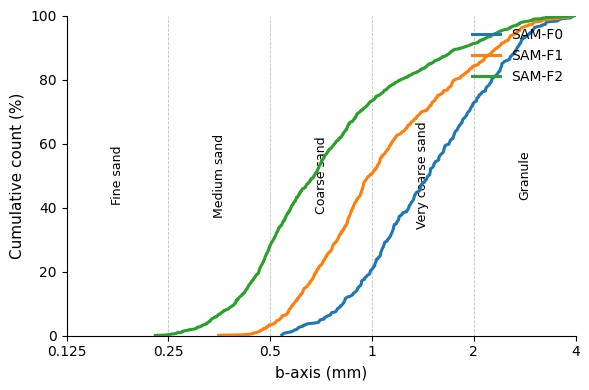

[(array([0.54083963, 0.54480476, 0.54787082, 0.56240081, 0.5768287 ,
         0.58426505, 0.58812443, 0.59920509, 0.60260928, 0.60403581,
         0.61158217, 0.62496361, 0.62520107, 0.63745393, 0.64375948,
         0.67806706, 0.69583   , 0.69705315, 0.70019021, 0.70226588,
         0.72192155, 0.72202712, 0.72415597, 0.7331139 , 0.73863559,
         0.75244358, 0.75432397, 0.75807634, 0.75921012, 0.77866116,
         0.78341327, 0.78627966, 0.78848872, 0.78929885, 0.79884601,
         0.80116375, 0.80861277, 0.80911058, 0.81534679, 0.81965847,
         0.8221322 , 0.82656342, 0.82741517, 0.8296378 , 0.83177781,
         0.83181403, 0.83537861, 0.84054416, 0.84978668, 0.8662355 ,
         0.8723723 , 0.87762897, 0.87853326, 0.8846482 , 0.89128278,
         0.89762049, 0.90066119, 0.90386086, 0.90708987, 0.90709314,
         0.91245639, 0.91623253, 0.92495844, 0.92632515, 0.92963736,
         0.9298735 , 0.92990249, 0.93006689, 0.93352594, 0.93681772,
         0.95045651, 0.95075009, 0

In [13]:
plot_gsd_cumulative(
    curves,
    size_column="minor_axis_length_mm",
    min_minor_axis_px=8,
    save_path=None,
)